# 1. Environment simulation module: `environment-simulation() → RadarSensorView`

In [43]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import decode
from osi_hfss import modules
from osi_hfss.data import load
from osi_hfss.messages import over_osi, preview
from osi_hfss.plots import plot_object_channels, plot_ray_geometry

# The inputs
ground_truth = load("front.groundtruth.bin")  # OSI GroundTruth of the front radar's scene
configuration = load("front.sensorviewconfiguration.bin")  # what the sensor model requests
scene = load("front.scene.json")  # radar properties of the objects, not in OSI

# The module and its output
sensor_view = modules.environment_simulation(ground_truth, configuration, scene)  # OSI SensorView
radar_sensor_view = sensor_view.radar_sensor_view[0]
config = radar_sensor_view.view_configuration
FREQUENCY = config.emitter_frequency

## The input, OSI `GroundTruth` and `RadarSensorViewConfiguration`

The scene is defined in OSI messages.

In [44]:
print("GroundTruth (first 2 of the moving objects, the host is object 0):")
print(preview(ground_truth))
print("\nRadarSensorViewConfiguration:")
print(preview(config))
print("\nRadar properties of the objects (not in OSI):")
for o in scene["objects"]:
    print(f"  object {o['id']} ({o['name']}): RCS {o['rcs_dbsm']:+.0f} dBsm, scattering matrix {np.real_if_close(np.array(o['scattering']) @ [1, 1j]).tolist()}")

GroundTruth (first 2 of the moving objects, the host is object 0):
version {
  version_major: 3
  version_minor: 8
  version_patch: 0
}
timestamp {
  seconds: 0
  nanos: 0
}
host_vehicle_id {
  value: 0
}
moving_object {
  id {
    value: 0
  }
  base {
    dimension {
      length: 4.6
      width: 1.9
      height: 1.5
    }
    position {
      x: 0
      y: 0
      z: 0
    }
    velocity {
      x: 20
    }
  }
  type: TYPE_VEHICLE
}
moving_object {
  id {
    value: 1
  }
  base {
    dimension {
      length: 4.5
      width: 1.8
      height: 1.5
    }
    position {
      x: 33
      y: -15
      z: 0.5
    }
    velocity {
      x: 15
      y: 0
      z: 0
    }
  }
  type: TYPE_VEHICLE
}
moving_object: ... 3 more

RadarSensorViewConfiguration:
sensor_id {
  value: 100
}
mounting_position {
  position {
    x: 3.5
    y: 0
    z: 0.5
  }
  orientation {
    yaw: 0
  }
}
field_of_view_horizontal: 2.0944
field_of_view_vertical: 0.349066
emitter_frequency: 7.675e+10
antenna_appl

## The rays

In [45]:
print(f"{'obj':>3} {'bounces':>7} {'path/2 [m]':>10} {'f_D [Hz]':>9} {'dep h/v [deg]':>14} {'arr h/v [deg]':>14} {'gain [dB]':>9}")
for r in radar_sensor_view.reflection:  # direct + two ground-bounce paths per object
    print(f"{r.object_id.value:3d} {r.number_of_interactions:7d} {decode.SPEED_OF_LIGHT * r.time_of_flight / 2:10.2f} {r.doppler_shift:9.0f} "
          f"{np.degrees(r.source_horizontal_angle):6.1f}/{np.degrees(r.source_vertical_angle):5.1f}  "
          f"{np.degrees(r.arrival_horizontal_angle):6.1f}/{np.degrees(r.arrival_vertical_angle):5.1f}  {r.signal_strength:9.1f}")
rays = decode.reflection_arrays(radar_sensor_view.reflection)
print("\nas arrays:", f"polarimetric_response {rays['polarimetric_response'].shape}, time_of_flight {rays['time_of_flight'].shape}, ...")

obj bounces path/2 [m]  f_D [Hz]  dep h/v [deg]  arr h/v [deg] gain [dB]
  1       1      33.09      2282  -27.0/  0.0   -27.0/  0.0     -131.9
  1       2      33.10      2282  -27.0/  0.0   -27.0/ -1.7     -134.9
  1       2      33.10      2282  -27.0/ -1.7   -27.0/  0.0     -134.9
  2       1      56.77     -2548    5.6/  0.0     5.6/  0.0     -139.3
  2       2      56.77     -2548    5.6/  0.0     5.6/ -1.0     -142.3
  2       2      56.77     -2548    5.6/ -1.0     5.6/  0.0     -142.3
  3       1      22.05      8591   33.0/  0.0    33.0/  0.0     -126.9
  3       2      22.06      8587   33.0/  0.0    33.0/ -2.6     -129.9
  3       2      22.06      8587   33.0/ -2.6    33.0/  0.0     -129.9

as arrays: polarimetric_response (9, 2, 2), time_of_flight (9,), ...


## Geometry

Top view.

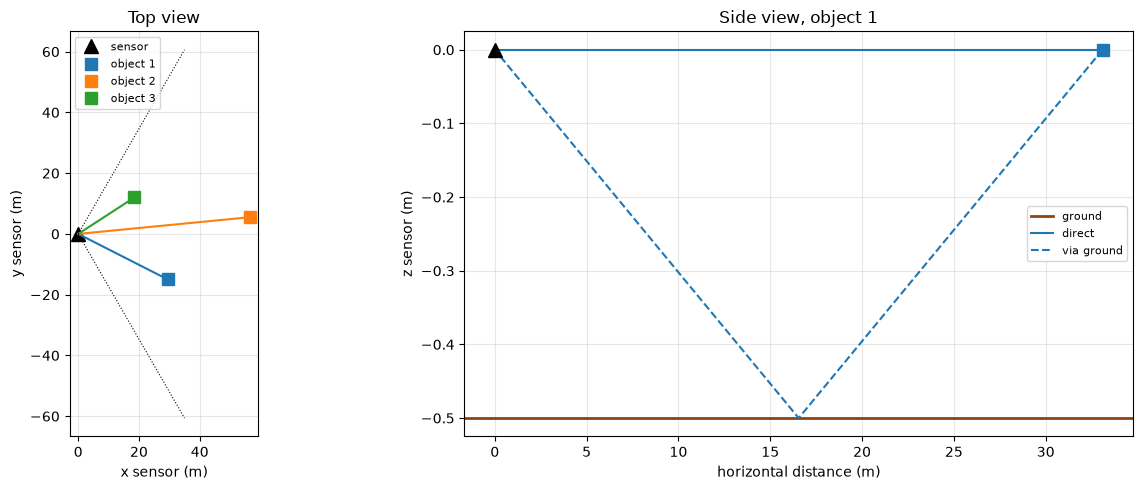

In [46]:
plot_ray_geometry(radar_sensor_view.reflection, config)
plt.tight_layout(); plt.show()

## Antenna-free channel over the chirp band

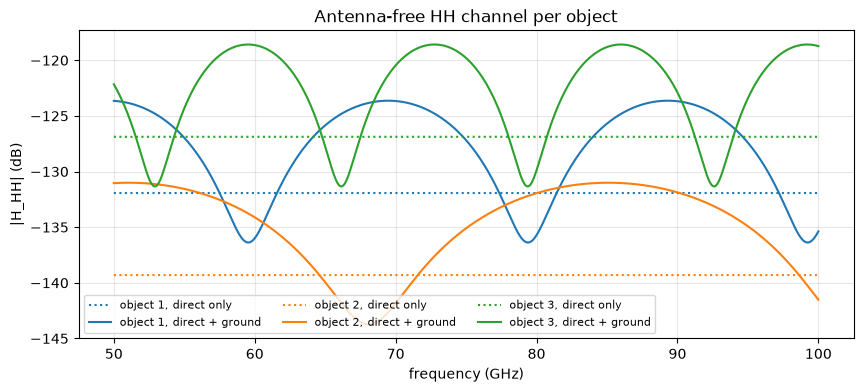

In [47]:
plot_object_channels(radar_sensor_view.reflection, np.linspace(50.0e9, 100.0e9, 2001))
plt.show()

## The output, OSI `RadarSensorView`

In [48]:
received = over_osi(radar_sensor_view)  # what the signal generator receives
assert received == radar_sensor_view
print(f"{len(received.reflection)} reflections, round trip exact\n")
print(preview(received, max_repeated=1))

  RadarSensorView         1.5 kB
9 reflections, round trip exact

view_configuration {
  sensor_id {
    value: 100
  }
  mounting_position {
    position {
      x: 3.5
      y: 0
      z: 0.5
    }
    orientation {
      yaw: 0
    }
  }
  field_of_view_horizontal: 2.0944
  field_of_view_vertical: 0.349066
  emitter_frequency: 7.675e+10
  antenna_application: ANTENNA_APPLICATION_SENSOR_MODEL
}
reflection {
  signal_strength: -131.932
  time_of_flight: 2.20783e-07
  doppler_shift: 2282.04
  source_horizontal_angle: -0.470404
  source_vertical_angle: 0
  arrival_horizontal_angle: -0.470404
  arrival_vertical_angle: 0
  polarimetric_response {
    m00 {
      amplitude: 2.53171e-07
      phase: 0
    }
    m01 {
      amplitude: 0
      phase: 0
    }
    m10 {
      amplitude: 0
      phase: 0
    }
    m11 {
      amplitude: 2.53171e-07
      phase: 0
    }
  }
  number_of_interactions: 1
  object_id {
    value: 1
  }
}
reflection: ... 8 more
